# 01 - Explore: Diabetes 130-US Hospitals (1999-2008)

**Goal of this notebook:** understand the raw data before changing anything.
We answer: how big is it, what are the columns, where is data missing, what does the target look like,
and do patients appear more than once?

Nothing here modifies `data/raw/`. Cleaning happens in notebook 02.

## 1. Setup
`PROJECT` points at the project folder whether you open this notebook from `notebooks/` or from the project root.
`pathlib.Path` builds file paths that work on Windows and Mac/Linux.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = PROJECT / "data" / "raw"
FIG = PROJECT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
print(RAW)

c:\Projects\readmission\data\raw


## 2. Load the data (carefully)

Three deliberate choices in `read_csv`:

1. **`na_values=["?"]`**: this dataset writes missing values as `"?"`, so we tell pandas to treat `"?"` as missing.
2. **`keep_default_na=False`**: by default pandas also turns strings like `"None"`, `"NA"`, `"NULL"` into missing.
   That would be wrong here: in `max_glu_serum` and `A1Cresult`, `"None"` means *the test was not done*, which is real information.
3. **`dtype=` for ID columns**: IDs are labels, not quantities (lesson from Project 1). Reading them as strings stops us
   from accidentally averaging them or feeding "admission type 6 > admission type 3" into a model.

Plus **`low_memory=False`**: pandas normally guesses each column's type in chunks. `payer_code` is empty for long
stretches, so one chunk looks numeric (all NaN) and another looks like text, and pandas warns about "mixed types".
Reading the whole file before guessing avoids that.

In [2]:
ID_COLS = ["encounter_id", "patient_nbr",
           "admission_type_id", "discharge_disposition_id", "admission_source_id"]

df = pd.read_csv(
    RAW / "diabetic_data.csv",
    na_values=["?"],
    keep_default_na=False,
    dtype={c: str for c in ID_COLS},
    low_memory=False,
)
print(df.shape)
df.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 3. Columns and types
`str` = text/categorical (pandas 3 shows text as `str`; older pandas showed `object`), `int64` = whole numbers. Only the count-style columns
(time in hospital, number of labs, medications, visits, diagnoses) should be numeric.

In [3]:
df.dtypes.value_counts()

str      42
int64     8
Name: count, dtype: int64

In [4]:
num_cols = df.select_dtypes("number").columns.tolist()
print("Numeric columns:", num_cols)
df[num_cols].describe().T

Numeric columns: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


## 4. Missing values
`isna().sum()` counts missing cells per column; dividing by the row count gives the percentage.
A column that is ~97% empty (`weight`) carries almost no signal and will likely be dropped in cleaning.

In [5]:
missing = (
    df.isna().sum()
      .to_frame("n_missing")
      .assign(pct_missing=lambda t: (100 * t["n_missing"] / len(df)).round(2))
      .query("n_missing > 0")
      .sort_values("n_missing", ascending=False)
)
missing

,n_missing,pct_missing
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


**"None" is a category, not missing.** Check that it survived loading:

In [6]:
for col in ["max_glu_serum", "A1Cresult"]:
    print(df[col].value_counts(dropna=False), "\n")

max_glu_serum
None    96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64 

A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64 



## 5. The target: `readmitted`
Three raw values: `<30` (readmitted within 30 days), `>30` (readmitted later), `NO`.
Our question is about **30-day** readmission, so the binary target is `<30` = 1, everything else = 0.

The **base rate** is the share of positives. If it is ~11%, a model that always says "no" is ~89% accurate
and completely useless, which is why we will use ROC-AUC, PR-AUC, precision and recall instead of accuracy.

In [7]:
print(df["readmitted"].value_counts())

y = (df["readmitted"] == "<30").astype(int)
base_rate = y.mean()
print(f"\nBase rate (<30 days): {base_rate:.2%}  ({y.sum():,} of {len(y):,} encounters)")

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Base rate (<30 days): 11.16%  (11,357 of 101,766 encounters)


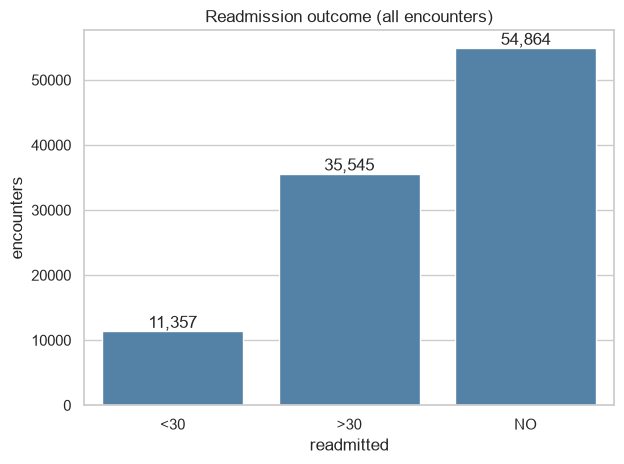

In [8]:
order = ["<30", ">30", "NO"]
ax = sns.countplot(data=df, x="readmitted", order=order, color="steelblue")
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
ax.set(title="Readmission outcome (all encounters)", xlabel="readmitted", ylabel="encounters")
plt.tight_layout()
plt.savefig(FIG / "01_target_distribution.png", dpi=150)
plt.show()

## 6. Repeat patients (leakage risk)
`encounter_id` = one hospital stay. `patient_nbr` = one person.
If the same person is in both train and test, the model can "recognise" them instead of learning general patterns,
so test scores look better than reality. That is **leakage**. We fix it in the split step by grouping on `patient_nbr`.

In [9]:
print("Encounters:     ", df["encounter_id"].nunique())
print("Unique patients:", df["patient_nbr"].nunique())

visits = df["patient_nbr"].value_counts()
print("\nEncounters per patient (how many patients had 1, 2, 3... stays):")
print(visits.value_counts().sort_index().head(10))
print(f"\nPatients with >1 encounter: {(visits > 1).sum():,} ({(visits > 1).mean():.1%})")
print(f"Rows belonging to repeat patients: {visits[visits > 1].sum():,} ({visits[visits > 1].sum() / len(df):.1%})")

Encounters:      101766
Unique patients: 71518

Encounters per patient (how many patients had 1, 2, 3... stays):
count
1     54745
2     10434
3      3328
4      1421
5       717
6       346
7       207
8       111
9        70
10       42
Name: count, dtype: int64

Patients with >1 encounter: 16,773 (23.5%)
Rows belonging to repeat patients: 47,021 (46.2%)


## 7. Decode the ID columns with `IDS_mapping.csv`
This file is **three small tables stacked in one CSV**, separated by blank rows.
A header row is recognisable because its first cell ends in `_id`. We walk through the rows and start a new
dictionary each time we hit a header.

In [10]:
raw_map = pd.read_csv(RAW / "IDS_mapping.csv", header=None, dtype=str, keep_default_na=False)

mappings = {}
current = None
for code_value, description in raw_map.itertuples(index=False):
    if code_value.endswith("_id"):          # header row -> start a new table
        current = code_value
        mappings[current] = {}
    elif code_value != "":                  # data row (skip blank separators)
        mappings[current][code_value] = description

{k: len(v) for k, v in mappings.items()}

{'admission_type_id': 8,
 'discharge_disposition_id': 30,
 'admission_source_id': 25}

## 8. Discharge disposition: who *cannot* be readmitted?
Some patients died (`Expired`) or went to hospice. They cannot be readmitted for a reason that has nothing to do
with care quality, so keeping them would teach the model a misleading pattern. We look at them here and decide in cleaning.

In [11]:
dd = df["discharge_disposition_id"].map(mappings["discharge_disposition_id"])
summary = (
    pd.DataFrame({"discharge": dd, "y": y})
      .groupby("discharge")
      .agg(encounters=("y", "size"), readmit_30_rate=("y", "mean"))
      .sort_values("encounters", ascending=False)
)
summary.head(12)

,encounters,readmit_30_rate
discharge,,
Discharged to home,60234,0.093004
Discharged/transferred to SNF,13954,0.146625
Discharged/transferred to home with home health service,12902,0.126957
NULL,3691,0.124357
Discharged/transferred to another short term hospital,2128,0.160714
Discharged/transferred to another rehab fac including rehab units of a hospital .,1993,0.276969
Expired,1642,0.000000
Discharged/transferred to another type of inpatient care institution,1184,0.208615
Not Mapped,989,0.093023


In [12]:
expired = dd.str.contains("Expired", case=False, na=False)
hospice = dd.str.contains("Hospice", case=False, na=False) & ~expired

for name, mask in [("Expired", expired), ("Hospice (alive)", hospice)]:
    print(f"{name:16s} encounters: {mask.sum():5,}   <30 readmissions: {y[mask].sum():3}   rate: {y[mask].mean():.2%}")

Expired          encounters: 1,652   <30 readmissions:   0   rate: 0.00%
Hospice (alive)  encounters:   771   <30 readmissions:  43   rate: 5.58%


Sanity check: patients who died should have **zero** readmissions. If that were not 0, the data would have a problem.
Hospice patients can come back, but rarely; whether to drop them is a judgement call we make (and document) in notebook 02.

## 9. First look at a few features vs. the target
Readmission rate = mean of the 0/1 target within each group. Compare each bar to the overall base rate (dashed line).

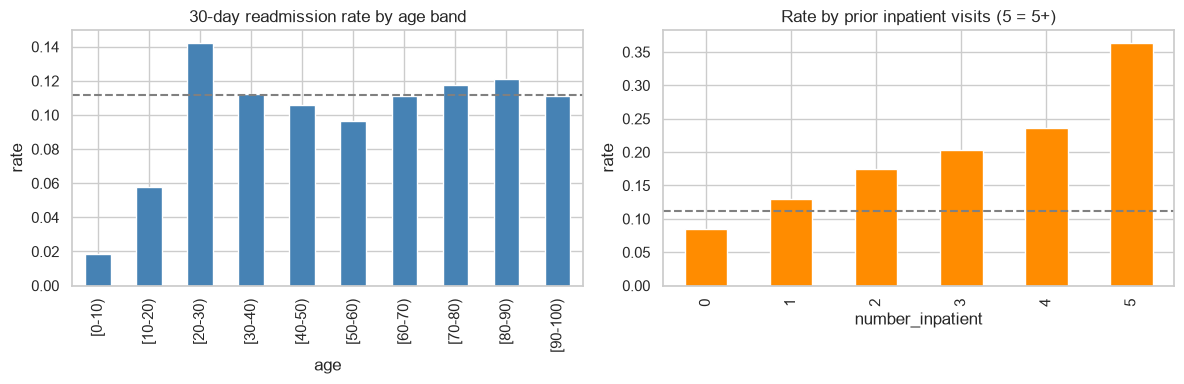

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

age_rate = y.groupby(df["age"]).mean()
age_rate.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title="30-day readmission rate by age band", xlabel="age", ylabel="rate")

inp = df["number_inpatient"].clip(upper=5)   # 5 = "5 or more"
inp_rate = y.groupby(inp).mean()
inp_rate.plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set(title="Rate by prior inpatient visits (5 = 5+)", xlabel="number_inpatient", ylabel="rate")

for ax in axes:
    ax.axhline(base_rate, ls="--", color="grey")
plt.tight_layout()
plt.savefig(FIG / "01_rate_by_age_and_prior_inpatient.png", dpi=150)
plt.show()